In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    classification_report,
    roc_auc_score
)

import statsmodels.api as sm
from scipy import stats

RANDOM_STATE = 100

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")
print("Random State:", RANDOM_STATE)


Libraries imported successfully!
Random State: 100


In [2]:
 url = "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset Shape: (7214, 53)


,id,name,first,last,compas_screening_date,sex,dob,age,age_cat,race,...,v_decile_score,v_score_text,v_screening_date,in_custody,out_custody,priors_count.1,start,end,event,two_year_recid
0,1,miguel hernandez,miguel,hernandez,2013-08-14,Male,1947-04-18,69,Greater than 45,Other,...,1,Low,2013-08-14,2014-07-07,2014-07-14,0,0,327,0,0
1,3,kevon dixon,kevon,dixon,2013-01-27,Male,1982-01-22,34,25 - 45,African-American,...,1,Low,2013-01-27,2013-01-26,2013-02-05,0,9,159,1,1
2,4,ed philo,ed,philo,2013-04-14,Male,1991-05-14,24,Less than 25,African-American,...,3,Low,2013-04-14,2013-06-16,2013-06-16,4,0,63,0,1
3,5,marcu brown,marcu,brown,2013-01-13,Male,1993-01-21,23,Less than 25,African-American,...,6,Medium,2013-01-13,NaN,NaN,1,0,1174,0,0
4,6,bouthy pierrelouis,bouthy,pierrelouis,2013-03-26,Male,1973-01-22,43,25 - 45,Other,...,1,Low,2013-03-26,NaN,NaN,2,0,1102,0,0


In [3]:

# ==========================================
# 3. DATASET EXPLORATION
# ==========================================

print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nStatistical Summary:")
display(df.describe(include="all").T)

print("\nRecidivism Target Distribution:")
print(df["is_recid"].value_counts(dropna=False))

print("\nCOMPAS Score Distribution:")
print(df["decile_score"].value_counts().sort_index())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7214 entries, 0 to 7213
Data columns (total 53 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       7214 non-null   int64  
 1   name                     7214 non-null   object 
 2   first                    7214 non-null   object 
 3   last                     7214 non-null   object 
 4   compas_screening_date    7214 non-null   object 
 5   sex                      7214 non-null   object 
 6   dob                      7214 non-null   object 
 7   age                      7214 non-null   int64  
 8   age_cat                  7214 non-null   object 
 9   race                     7214 non-null   object 
 10  juv_fel_count            7214 non-null   int64  
 11  decile_score             7214 non-null   int64  
 12  juv_misd_count           7214 non-null   int64  
 13  juv_other_count          7214 non-null   int64  
 14  pri

,0
violent_recid,7214
vr_charge_degree,6395
vr_offense_date,6395
vr_case_number,6395
vr_charge_desc,6395
c_arrest_date,6077
r_jail_in,4898
r_days_from_arrest,4898
r_jail_out,4898
r_charge_desc,3801



Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,7214.0,NaN,NaN,NaN,5501.255753,3175.70687,1.0,2735.25,5509.5,8246.5,11001.0
name,7214,7158,anthony smith,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
first,7214,2800,michael,149,NaN,NaN,NaN,NaN,NaN,NaN,NaN
last,7214,3950,williams,83,NaN,NaN,NaN,NaN,NaN,NaN,NaN
compas_screening_date,7214,690,2013-03-20,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,7214,2,Male,5819,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dob,7214,5452,1994-07-15,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,7214.0,NaN,NaN,NaN,34.817993,11.888922,18.0,25.0,31.0,42.0,96.0
age_cat,7214,3,25 - 45,4109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,7214,6,African-American,3696,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Recidivism Target Distribution:
is_recid
0    3743
1    3471
Name: count, dtype: int64

COMPAS Score Distribution:
decile_score
1     1440
2      941
3      747
4      769
5      681
6      641
7      592
8      512
9      508
10     383
Name: count, dtype: int64


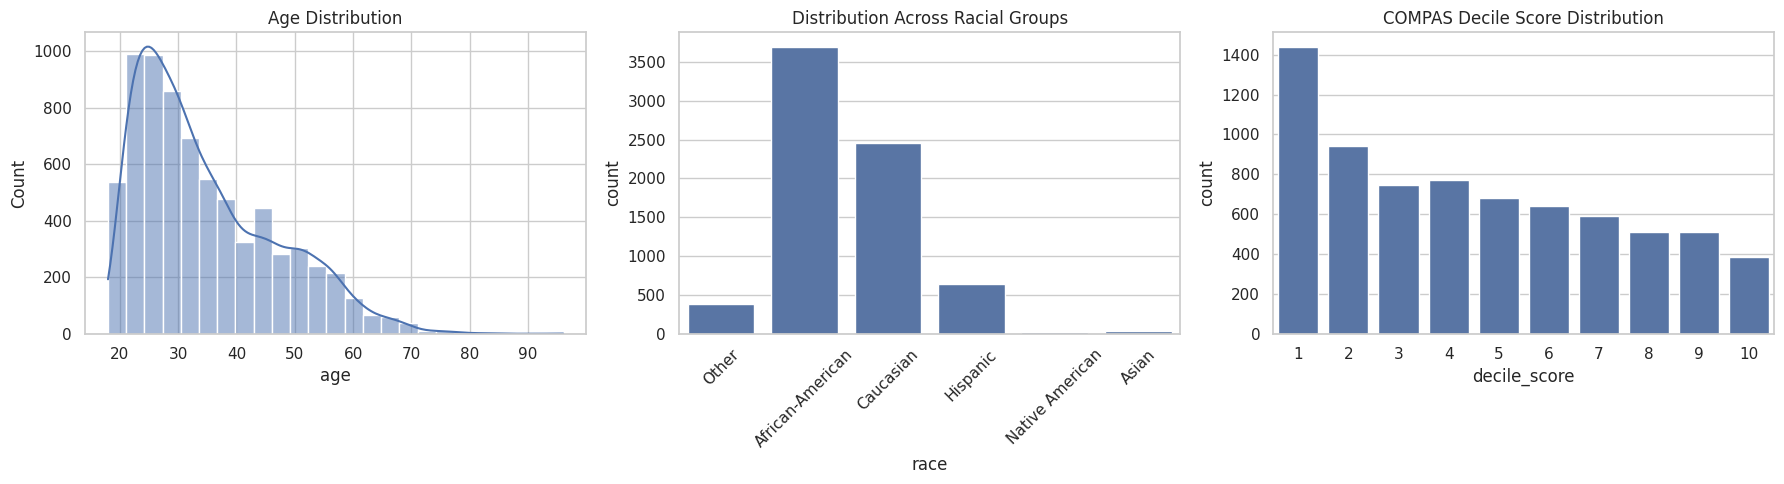

In [4]:

# ==========================================
# 4. EXPLORATORY DATA ANALYSIS
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["age"], bins=25, kde=True, ax=axes[0])
axes[0].set_title("Age Distribution")

sns.countplot(data=df, x="race", ax=axes[1])
axes[1].set_title("Distribution Across Racial Groups")
axes[1].tick_params(axis="x", rotation=45)

sns.countplot(data=df, x="decile_score", ax=axes[2])
axes[2].set_title("COMPAS Decile Score Distribution")

plt.tight_layout()
plt.show()


In [5]:

# ==========================================
# 5. TARGET VALIDATION
# ==========================================

print("is_recid unique values:")
print(sorted(df["is_recid"].dropna().unique()))

print("\ntwo_year_recid unique values:")
print(sorted(df["two_year_recid"].dropna().unique()))

print("\nComparison between the two outcome columns:")
display(pd.crosstab(df["is_recid"], df["two_year_recid"],
                    margins=True))


is_recid unique values:
[np.int64(0), np.int64(1)]

two_year_recid unique values:
[np.int64(0), np.int64(1)]

Comparison between the two outcome columns:


two_year_recid,0,1,All
is_recid,,,
0,3743,0,3743
1,220,3251,3471
All,3963,3251,7214


In [6]:

# ==========================================
# 6. FEATURE SELECTION
# ==========================================

numerical_features = [
    "age",
    "priors_count",
    "juv_fel_count",
    "juv_misd_count",
    "juv_other_count"
]

categorical_features = [
    "sex",
    "race",
    "c_charge_degree"
]

selected_features = numerical_features + categorical_features

# Model A target
y_linear = df["decile_score"].copy()

# Model B target
y_logistic = df["is_recid"].copy()

# Common predictor dataset
X = df[selected_features].copy()

print("Predictor dataset shape:", X.shape)
print("\nNumerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nMissing values in selected features:")
print(X.isnull().sum())


Predictor dataset shape: (7214, 8)

Numerical features:
['age', 'priors_count', 'juv_fel_count', 'juv_misd_count', 'juv_other_count']

Categorical features:
['sex', 'race', 'c_charge_degree']

Missing values in selected features:
age                0
priors_count       0
juv_fel_count      0
juv_misd_count     0
juv_other_count    0
sex                0
race               0
c_charge_degree    0
dtype: int64


In [7]:

# ==========================================
# 7. MISSING VALUE HANDLING
# ==========================================

print("Missing values before treatment:")
print(X.isnull().sum())

for col in numerical_features:
    X[col] = X[col].fillna(X[col].median())

for col in categorical_features:
    X[col] = X[col].fillna(X[col].mode()[0])

print("\nMissing values after treatment:")
print(X.isnull().sum().sum())


Missing values before treatment:
age                0
priors_count       0
juv_fel_count      0
juv_misd_count     0
juv_other_count    0
sex                0
race               0
c_charge_degree    0
dtype: int64

Missing values after treatment:
0


In [8]:

# ==========================================
# 8. CATEGORICAL ENCODING
# ==========================================

X_encoded = pd.get_dummies(
    X,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

print("Shape after encoding:", X_encoded.shape)

display(X_encoded.head())


Shape after encoding: (7214, 12)


,age,priors_count,juv_fel_count,juv_misd_count,juv_other_count,sex_Male,race_Asian,race_Caucasian,race_Hispanic,race_Native American,race_Other,c_charge_degree_M
0,69,0,0,0,0,1,0,0,0,0,1,0
1,34,0,0,0,0,1,0,0,0,0,0,0
2,24,4,0,0,1,1,0,0,0,0,0,0
3,23,1,0,1,0,1,0,0,0,0,0,0
4,43,2,0,0,0,1,0,0,0,0,1,0


In [9]:

# ==========================================
# 9. OUTLIER DETECTION USING IQR
# ==========================================

outlier_summary = []

for col in numerical_features:

    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = X[
        (X[col] < lower_bound) |
        (X[col] > upper_bound)
    ]

    outlier_summary.append({
        "Feature": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": round(
            len(outliers) / len(X) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df)


,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,age,-0.5,67.5,61,0.85
1,priors_count,-7.5,12.5,455,6.31
2,juv_fel_count,0.0,0.0,282,3.91
3,juv_misd_count,0.0,0.0,415,5.75
4,juv_other_count,0.0,0.0,523,7.25


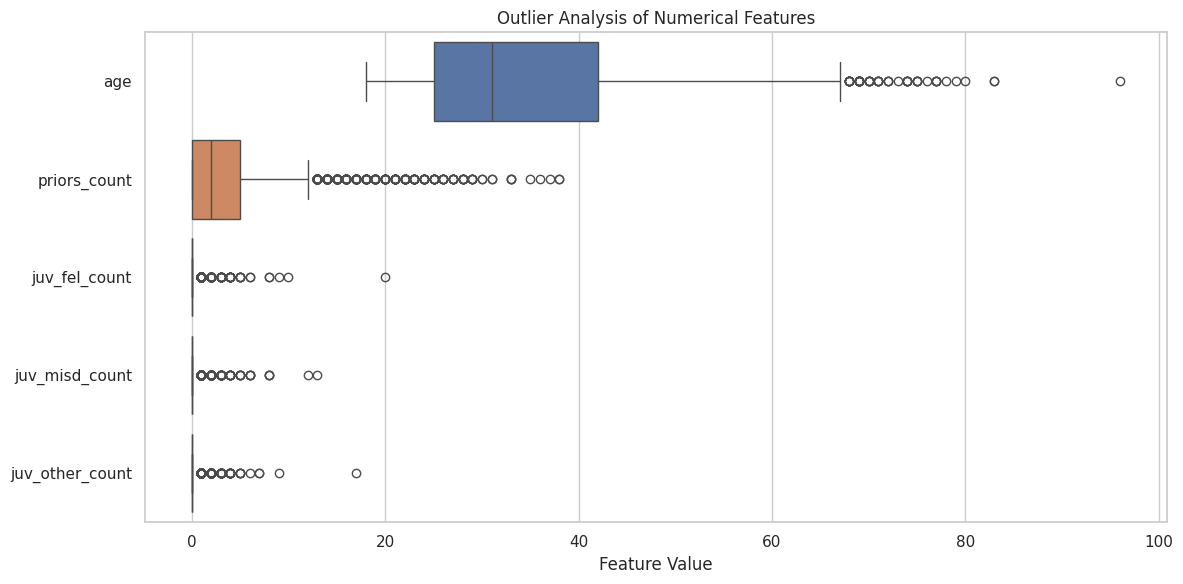

In [10]:

# ==========================================
# 10. BOXPLOT ANALYSIS
# ==========================================

plt.figure(figsize=(12, 6))

sns.boxplot(data=X[numerical_features], orient="h")

plt.title("Outlier Analysis of Numerical Features")
plt.xlabel("Feature Value")
plt.tight_layout()
plt.show()


In [11]:

# ==========================================
# 11. TRAIN-TEST SPLIT
# ==========================================

X_train, X_test, yA_train, yA_test, yB_train, yB_test = train_test_split(
    X_encoded,
    y_linear,
    y_logistic,
    test_size=0.30,
    random_state=100
)

# Preserve original column names
X_train = X_train.copy()
X_test = X_test.copy()

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# ==========================================
# 12. FEATURE SCALING
# ==========================================

scaler = StandardScaler()

X_train[numerical_features] = scaler.fit_transform(
    X_train[numerical_features]
)

X_test[numerical_features] = scaler.transform(
    X_test[numerical_features]
)

print("\nScaling completed!")
print("Random state:", 100)

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nModel A target distribution:")
print(yA_train.value_counts())

print("\nModel B target distribution:")
print(yB_train.value_counts())


Training samples: 5049
Testing samples: 2165

Scaling completed!
Random state: 100

Training data shape: (5049, 12)
Testing data shape: (2165, 12)

Model A target distribution:
decile_score
1     1000
2      677
4      555
3      504
5      467
6      433
7      410
9      371
8      368
10     264
Name: count, dtype: int64

Model B target distribution:
is_recid
0    2600
1    2449
Name: count, dtype: int64


In [12]:

# ==========================================
# PART 1 - MODEL A: LINEAR REGRESSION
# ==========================================

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Initialize model
linear_model = LinearRegression()

# Train model
linear_model.fit(X_train, yA_train)

# Predict decile scores
linear_predictions = linear_model.predict(X_test)

# Evaluate regression
linear_mse = mean_squared_error(yA_test, linear_predictions)
linear_rmse = np.sqrt(linear_mse)
linear_mae = mean_absolute_error(yA_test, linear_predictions)
linear_r2 = r2_score(yA_test, linear_predictions)

print("MODEL A: LINEAR REGRESSION")
print("--------------------------------")
print("Mean Squared Error:", round(linear_mse, 4))
print("Root Mean Squared Error:", round(linear_rmse, 4))
print("Mean Absolute Error:", round(linear_mae, 4))
print("R2 Score:", round(linear_r2, 4))

print("\nFirst 10 predictions:")
print(np.round(linear_predictions[:10], 2))


MODEL A: LINEAR REGRESSION
--------------------------------
Mean Squared Error: 4.5766
Root Mean Squared Error: 2.1393
Mean Absolute Error: 1.7298
R2 Score: 0.4318

First 10 predictions:
[2.69 4.1  2.51 4.22 4.12 1.59 3.75 4.67 2.26 3.26]


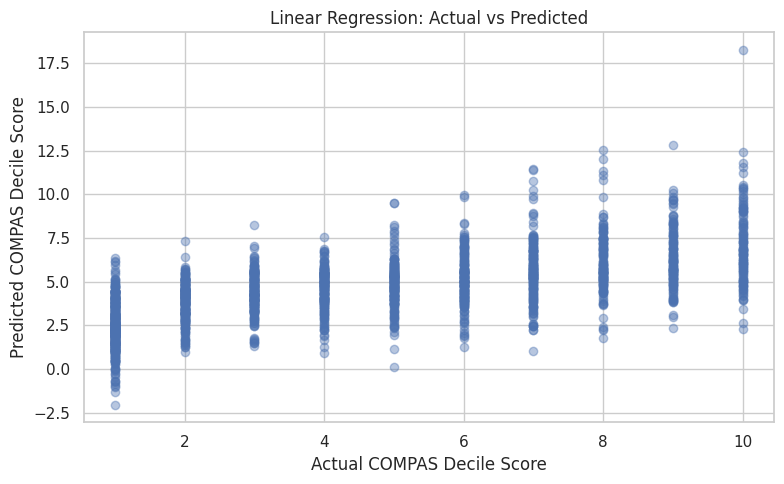

In [13]:

plt.figure(figsize=(8, 5))

plt.scatter(
    yA_test,
    linear_predictions,
    alpha=0.4
)

plt.xlabel("Actual COMPAS Decile Score")
plt.ylabel("Predicted COMPAS Decile Score")
plt.title("Linear Regression: Actual vs Predicted")

plt.tight_layout()
plt.show()


In [14]:

# ==========================================
# PART 1 - MODEL B: LOGISTIC REGRESSION
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Initialize model
logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=100
)

# Train model
logistic_model.fit(X_train, yB_train)

# Predict probabilities
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

# Classify using default threshold 0.5
logistic_predictions = (
    logistic_probabilities >= 0.5
).astype(int)

# Evaluate classification
logistic_accuracy = accuracy_score(
    yB_test, logistic_predictions
)

logistic_precision = precision_score(
    yB_test, logistic_predictions
)

logistic_recall = recall_score(
    yB_test, logistic_predictions
)

logistic_f1 = f1_score(
    yB_test, logistic_predictions
)

logistic_auc = roc_auc_score(
    yB_test, logistic_probabilities
)

print("MODEL B: LOGISTIC REGRESSION")
print("--------------------------------")
print("Accuracy:", round(logistic_accuracy, 4))
print("Precision:", round(logistic_precision, 4))
print("Recall:", round(logistic_recall, 4))
print("F1 Score:", round(logistic_f1, 4))
print("ROC-AUC:", round(logistic_auc, 4))

print("\nClassification Report:")
print(classification_report(yB_test, logistic_predictions))


MODEL B: LOGISTIC REGRESSION
--------------------------------
Accuracy: 0.661
Precision: 0.6449
Recall: 0.6272
F1 Score: 0.6359
ROC-AUC: 0.7227

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.69      0.68      1143
           1       0.64      0.63      0.64      1022

    accuracy                           0.66      2165
   macro avg       0.66      0.66      0.66      2165
weighted avg       0.66      0.66      0.66      2165



In [15]:

# ==========================================
# PART 1 - THRESHOLD COMPARISON
# ==========================================

# Median threshold for Linear Regression
linear_threshold = np.median(linear_predictions)

# Convert Linear Regression predictions into classes
linear_binary_predictions = (
    linear_predictions >= linear_threshold
).astype(int)

# Logistic Regression already uses threshold 0.5
logistic_binary_predictions = (
    logistic_probabilities >= 0.5
).astype(int)

# Confusion matrix comparing both approaches
comparison_matrix = confusion_matrix(
    linear_binary_predictions,
    logistic_binary_predictions,
    labels=[0, 1]
)

print("PART 1: MODEL AGREEMENT")
print("--------------------------------")

print("Linear Regression Median Threshold:",
      round(linear_threshold, 4))

print("\nConfusion Matrix:")
print(comparison_matrix)

# Calculate agreement and disagreement
mismatch = (
    linear_binary_predictions != logistic_binary_predictions
)

mismatch_count = mismatch.sum()
total_test = len(mismatch)

mismatch_percentage = (
    mismatch_count / total_test
) * 100

agreement_count = total_test - mismatch_count

agreement_percentage = (
    agreement_count / total_test
) * 100

print("\nTotal Test Individuals:", total_test)
print("Agreement Count:", agreement_count)
print("Disagreement Count:", mismatch_count)

print("Agreement Percentage:",
      round(agreement_percentage, 2), "%")

print("Mismatch Percentage:",
      round(mismatch_percentage, 2), "%")


PART 1: MODEL AGREEMENT
--------------------------------
Linear Regression Median Threshold: 4.5689

Confusion Matrix:
[[1016   62]
 [ 155  932]]

Total Test Individuals: 2165
Agreement Count: 1948
Disagreement Count: 217
Agreement Percentage: 89.98 %
Mismatch Percentage: 10.02 %


In [ ]:

# ==========================================
# PART 2.1 - SIMPSON'S PARADOX HUNT
# ==========================================

import statsmodels.api as sm
import pandas as pd
import numpy as np

# 1. Identify racial groups corresponding to training observations
train_race = df.loc[X_train.index, "race"]

# 2. Identify common predictors
# Race dummy variables are excluded from subgroup models
# because race is constant within each subgroup.

subgroup_features = [
    col for col in X_train.columns
    if not col.startswith("race_")
]

# 3. Function to fit logistic regression using Statsmodels

def fit_logistic_analysis(X_data, y_data, model_name):

    X_data = sm.add_constant(X_data, has_constant="add")

    model = sm.GLM(
        y_data,
        X_data,
        family=sm.families.Binomial()
    ).fit()

    return model


# ==========================================
# MODEL 1: FULL TRAINING DATA
# ==========================================

full_model = fit_logistic_analysis(
    X_train,
    yB_train,
    "Full Dataset"
)


# ==========================================
# MODEL 2: AFRICAN-AMERICAN SUBGROUP
# ==========================================

aa_mask = train_race == "African-American"

X_aa = X_train.loc[aa_mask, subgroup_features]
y_aa = yB_train.loc[aa_mask]

aa_model = fit_logistic_analysis(
    X_aa,
    y_aa,
    "African-American"
)


# ==========================================
# MODEL 3: CAUCASIAN SUBGROUP
# ==========================================

caucasian_mask = train_race == "Caucasian"

X_caucasian = X_train.loc[
    caucasian_mask, subgroup_features
]

y_caucasian = yB_train.loc[caucasian_mask]

caucasian_model = fit_logistic_analysis(
    X_caucasian,
    y_caucasian,
    "Caucasian"
)


# ==========================================
# EXTRACT PRIORS_COUNT COEFFICIENTS
# ==========================================

models = {
    "Full Dataset": full_model,
    "African-American": aa_model,
    "Caucasian": caucasian_model
}

results = []

for name, model in models.items():

    coefficient = model.params["priors_count"]

    confidence_interval = model.conf_int().loc[
        "priors_count"
    ]

    p_value = model.pvalues["priors_count"]

    results.append({
        "Group": name,
        "Sample Size": int(model.nobs),
        "Coefficient": coefficient,
        "Odds Ratio": np.exp(coefficient),
        "CI Lower": confidence_interval.iloc[0],
        "CI Upper": confidence_interval.iloc[1],
        "P-value": p_value
    })

simpson_results = pd.DataFrame(results)

print("SIMPSON'S PARADOX ANALYSIS")
print("================================")

display(
    simpson_results.round(5)
)

print("\nSubgroup sample sizes:")
print("African-American:", len(y_aa))
print("Caucasian:", len(y_caucasian))
print("Full dataset:", len(yB_train))


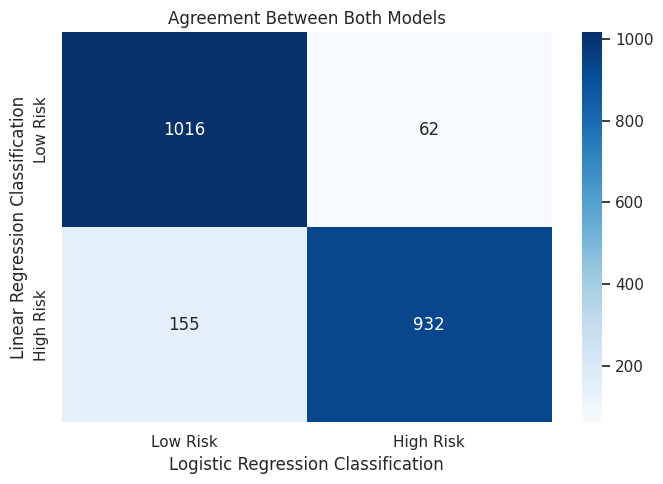

In [16]:

plt.figure(figsize=(7, 5))

sns.heatmap(
    comparison_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low Risk", "High Risk"],
    yticklabels=["Low Risk", "High Risk"]
)

plt.xlabel("Logistic Regression Classification")
plt.ylabel("Linear Regression Classification")
plt.title("Agreement Between Both Models")

plt.tight_layout()
plt.show()


In [17]:

# ==========================================
# PART 2.1 - SIMPSON'S PARADOX HUNT
# ==========================================

import statsmodels.api as sm
import pandas as pd
import numpy as np

# 1. Identify racial groups corresponding to training observations
train_race = df.loc[X_train.index, "race"]

# 2. Identify common predictors
# Race dummy variables are excluded from subgroup models
# because race is constant within each subgroup.

subgroup_features = [
    col for col in X_train.columns
    if not col.startswith("race_")
]

# 3. Function to fit logistic regression using Statsmodels

def fit_logistic_analysis(X_data, y_data, model_name):

    X_data = sm.add_constant(X_data, has_constant="add")

    model = sm.GLM(
        y_data,
        X_data,
        family=sm.families.Binomial()
    ).fit()

    return model


# ==========================================
# MODEL 1: FULL TRAINING DATA
# ==========================================

full_model = fit_logistic_analysis(
    X_train,
    yB_train,
    "Full Dataset"
)


# ==========================================
# MODEL 2: AFRICAN-AMERICAN SUBGROUP
# ==========================================

aa_mask = train_race == "African-American"

X_aa = X_train.loc[aa_mask, subgroup_features]
y_aa = yB_train.loc[aa_mask]

aa_model = fit_logistic_analysis(
    X_aa,
    y_aa,
    "African-American"
)


# ==========================================
# MODEL 3: CAUCASIAN SUBGROUP
# ==========================================

caucasian_mask = train_race == "Caucasian"

X_caucasian = X_train.loc[
    caucasian_mask, subgroup_features
]

y_caucasian = yB_train.loc[caucasian_mask]

caucasian_model = fit_logistic_analysis(
    X_caucasian,
    y_caucasian,
    "Caucasian"
)


# ==========================================
# EXTRACT PRIORS_COUNT COEFFICIENTS
# ==========================================

models = {
    "Full Dataset": full_model,
    "African-American": aa_model,
    "Caucasian": caucasian_model
}

results = []

for name, model in models.items():

    coefficient = model.params["priors_count"]

    confidence_interval = model.conf_int().loc[
        "priors_count"
    ]

    p_value = model.pvalues["priors_count"]

    results.append({
        "Group": name,
        "Sample Size": int(model.nobs),
        "Coefficient": coefficient,
        "Odds Ratio": np.exp(coefficient),
        "CI Lower": confidence_interval.iloc[0],
        "CI Upper": confidence_interval.iloc[1],
        "P-value": p_value
    })

simpson_results = pd.DataFrame(results)

print("SIMPSON'S PARADOX ANALYSIS")
print("================================")

display(
    simpson_results.round(5)
)

print("\nSubgroup sample sizes:")
print("African-American:", len(y_aa))
print("Caucasian:", len(y_caucasian))
print("Full dataset:", len(yB_train))


SIMPSON'S PARADOX ANALYSIS


,Group,Sample Size,Coefficient,Odds Ratio,CI Lower,CI Upper,P-value
0,Full Dataset,5049,0.74551,2.10751,0.66035,0.83066,0.0
1,African-American,2576,0.71184,2.03773,0.60384,0.81983,0.0
2,Caucasian,1722,0.83858,2.31309,0.67082,1.00635,0.0



Subgroup sample sizes:
African-American: 2576
Caucasian: 1722
Full dataset: 5049


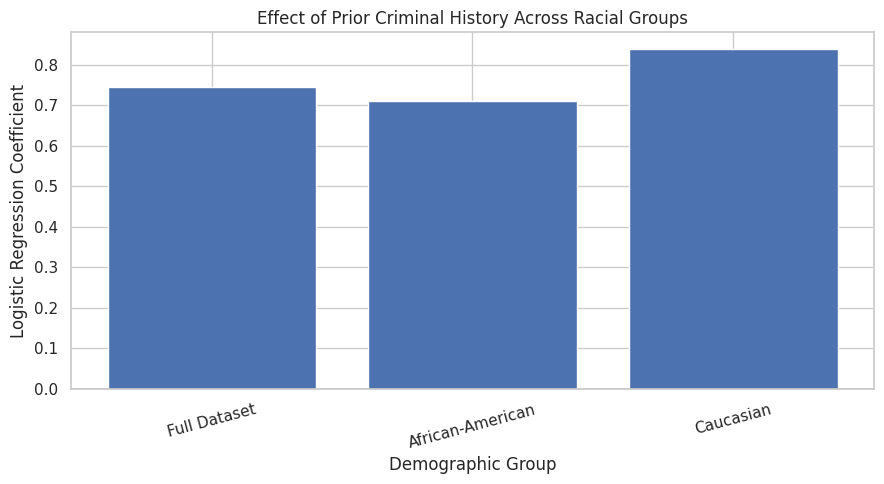

In [18]:

# ==========================================
# COEFFICIENT COMPARISON
# ==========================================

plt.figure(figsize=(9, 5))

plt.bar(
    simpson_results["Group"],
    simpson_results["Coefficient"]
)

plt.axhline(0, color="black", linewidth=1)

plt.ylabel("Logistic Regression Coefficient")
plt.xlabel("Demographic Group")

plt.title(
    "Effect of Prior Criminal History "
    "Across Racial Groups"
)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [19]:

# ==========================================
# PART 2.1 - FORMAL INTERACTION TEST
# ==========================================

# Keep only African-American and Caucasian observations
race_subset_mask = train_race.isin(
    ["African-American", "Caucasian"]
)

X_interaction = X_train.loc[
    race_subset_mask, subgroup_features
].copy()

y_interaction = yB_train.loc[race_subset_mask]

race_interaction = train_race.loc[race_subset_mask]

# 1 = African-American, 0 = Caucasian
X_interaction["race_AA"] = (
    race_interaction == "African-American"
).astype(int)

# Interaction between prior crimes and race
X_interaction["priors_race_interaction"] = (
    X_interaction["priors_count"] *
    X_interaction["race_AA"]
)

# Fit logistic regression
X_interaction = sm.add_constant(
    X_interaction,
    has_constant="add"
)

interaction_model = sm.GLM(
    y_interaction,
    X_interaction,
    family=sm.families.Binomial()
).fit()

print(interaction_model.summary())

print("\nInteraction coefficient:")
print(
    interaction_model.params[
        "priors_race_interaction"
    ]
)

print("\nInteraction p-value:")
print(
    interaction_model.pvalues[
        "priors_race_interaction"
    ]
)

print("\nInteraction 95% confidence interval:")
print(
    interaction_model.conf_int().loc[
        "priors_race_interaction"
    ]
)


                 Generalized Linear Model Regression Results                  
Dep. Variable:               is_recid   No. Observations:                 4298
Model:                            GLM   Df Residuals:                     4288
Model Family:                Binomial   Df Model:                            9
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2640.6
Date:                Thu, 19 Nov 2026   Deviance:                       5281.1
Time:                        16:09:59   Pearson chi2:                 4.56e+03
No. Iterations:                     5   Pseudo R-squ. (CS):             0.1457
Covariance Type:            nonrobust                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

In [24]:

# ==========================================
# PART 2.2 - OMITTED VARIABLE BIAS
# ==========================================

# Full model: all predictors
X_full_ovb = sm.add_constant(
    X_train,
    has_constant="add"
)

full_ovb_model = sm.GLM(
    yB_train,
    X_full_ovb,
    family=sm.families.Binomial()
).fit()


# Reduced model: remove AGE
X_reduced_ovb = X_train.drop(
    columns=["age"]
)

X_reduced_ovb = sm.add_constant(
    X_reduced_ovb,
    has_constant="add"
)

reduced_ovb_model = sm.GLM(
    yB_train,
    X_reduced_ovb,
    family=sm.families.Binomial()
).fit()


# ==========================================
# COMPARE COEFFICIENTS
# ==========================================
selected_coefficients = [
    "priors_count",
    "juv_fel_count",
    "juv_misd_count",
    "sex_Male",
    "race_Caucasian"
]

ovb_results = []

for feature in selected_coefficients:

    before = full_ovb_model.params[feature]
    after = reduced_ovb_model.params[feature]

    absolute_change = after - before

    percentage_change = (
        abs(absolute_change) /
        abs(before)
    ) * 100 if before != 0 else np.nan

    ovb_results.append({
        "Feature": feature,
        "Full Coefficient": before,
        "Reduced Coefficient": after,
        "Absolute Change": absolute_change,
        "Percentage Change": percentage_change
    })


ovb_df = pd.DataFrame(ovb_results)

print("OMITTED VARIABLE BIAS ANALYSIS")
print("================================")
print("Dropped variable: age")

display(ovb_df.round(5))


# ==========================================
# IDENTIFY LARGEST COEFFICIENT SHIFT
# ==========================================

largest_shift = ovb_df.loc[
    ovb_df["Percentage Change"].idxmax()
]

print("\nLargest coefficient shift:")
print("Feature:", largest_shift["Feature"])
print("Percentage change:",
      round(largest_shift["Percentage Change"], 2), "%")


OMITTED VARIABLE BIAS ANALYSIS
Dropped variable: age


,Feature,Full Coefficient,Reduced Coefficient,Absolute Change,Percentage Change
0,priors_count,0.74551,0.58002,-0.16549,22.19773
1,juv_fel_count,0.09438,0.15533,0.06095,64.58476
2,juv_misd_count,0.02301,0.11031,0.08729,379.34741
3,sex_Male,0.37206,0.35365,-0.01841,4.94873
4,race_Caucasian,-0.06698,-0.30103,-0.23406,349.45074



Largest coefficient shift:
Feature: juv_misd_count
Percentage change: 379.35 %


In [21]:
print("Available race columns:")

for col in X_train.columns:
    if "race" in col.lower():
        print(col)

Available race columns:
race_Asian
race_Caucasian
race_Hispanic
race_Native American
race_Other


In [22]:
selected_coefficients = [
    "priors_count",
    "juv_fel_count",
    "juv_misd_count",
    "sex_Male"
]

# Automatically find the available race dummy
race_columns = [
    col for col in X_train.columns
    if col.startswith("race_")
]

print("Available race columns:", race_columns)

selected_coefficients += race_columns[:1]

print("Final selected predictors:", selected_coefficients)

Available race columns: ['race_Asian', 'race_Caucasian', 'race_Hispanic', 'race_Native American', 'race_Other']
Final selected predictors: ['priors_count', 'juv_fel_count', 'juv_misd_count', 'sex_Male', 'race_Asian']


In [23]:
ovb_results = []

for feature in selected_coefficients:

    before = full_ovb_model.params[feature]
    after = reduced_ovb_model.params[feature]

    absolute_change = after - before

    percentage_change = (
        abs(absolute_change) / abs(before) * 100
        if before != 0 else np.nan
    )

    ovb_results.append({
        "Feature": feature,
        "Full Coefficient": before,
        "Reduced Coefficient": after,
        "Absolute Change": absolute_change,
        "Percentage Change": percentage_change
    })

ovb_df = pd.DataFrame(ovb_results)

display(ovb_df.round(5))

largest_shift = ovb_df.loc[
    ovb_df["Percentage Change"].idxmax()
]

print("\nLargest coefficient shift:")
print(largest_shift)

,Feature,Full Coefficient,Reduced Coefficient,Absolute Change,Percentage Change
0,priors_count,0.74551,0.58002,-0.16549,22.19773
1,juv_fel_count,0.09438,0.15533,0.06095,64.58476
2,juv_misd_count,0.02301,0.11031,0.08729,379.34741
3,sex_Male,0.37206,0.35365,-0.01841,4.94873
4,race_Asian,-1.01251,-1.05697,-0.04447,4.39196



Largest coefficient shift:
Feature                juv_misd_count
Full Coefficient             0.023012
Reduced Coefficient          0.110306
Absolute Change              0.087295
Percentage Change           379.34741
Name: 2, dtype: object


In [25]:
# Create a dataframe containing actual and predicted outcomes

adversarial_df = pd.DataFrame({
    "actual": yB_test,
    "probability": logistic_probabilities
}, index=X_test.index)

# Identify confidently incorrect predictions
adversarial_df["error_type"] = np.where(
    (adversarial_df["probability"] >= 0.75) &
    (adversarial_df["actual"] == 0),
    "Confident False Positive",
    np.where(
        (adversarial_df["probability"] <= 0.25) &
        (adversarial_df["actual"] == 1),
        "Confident False Negative",
        "Other"
    )
)

# Keep only confidently incorrect cases
adversarial_df = adversarial_df[
    adversarial_df["error_type"] != "Other"
]

print("Confidently incorrect cases:", len(adversarial_df))
print("Percentage of test set:",
      round(len(adversarial_df) / len(yB_test) * 100, 2), "%")

display(adversarial_df.head())

Confidently incorrect cases: 108
Percentage of test set: 4.99 %


,actual,probability,error_type
1389,1,0.230374,Confident False Negative
3009,1,0.210727,Confident False Negative
3132,0,0.873051,Confident False Positive
5726,0,0.793024,Confident False Positive
4022,0,0.753552,Confident False Positive


In [26]:
# Add original demographic and criminal-history information
columns_to_show = [
    "age",
    "sex",
    "race",
    "priors_count",
    "juv_fel_count",
    "juv_misd_count",
    "c_charge_degree"
]

adversarial_details = adversarial_df.join(
    df.loc[adversarial_df.index, columns_to_show]
)

display(adversarial_details.head(10))

,actual,probability,error_type,age,sex,race,priors_count,juv_fel_count,juv_misd_count,c_charge_degree
1389,1,0.230374,Confident False Negative,55,Male,Caucasian,2,0,0,M
3009,1,0.210727,Confident False Negative,52,Male,African-American,0,0,0,M
3132,0,0.873051,Confident False Positive,40,Male,African-American,15,1,0,F
5726,0,0.793024,Confident False Positive,36,Male,Caucasian,12,0,0,F
4022,0,0.753552,Confident False Positive,32,Male,African-American,9,0,0,F
1055,0,0.826728,Confident False Positive,57,Male,African-American,19,0,0,F
4966,0,0.762285,Confident False Positive,33,Male,Caucasian,10,0,0,F
4872,1,0.236101,Confident False Negative,52,Male,African-American,0,0,0,F
2182,1,0.246702,Confident False Negative,30,Female,Hispanic,0,0,0,M
219,1,0.153506,Confident False Negative,51,Female,Caucasian,0,0,0,M


In [27]:
print("Error type distribution:")
display(adversarial_details["error_type"].value_counts())

print("\nRace distribution:")
display(adversarial_details["race"].value_counts(normalize=True) * 100)

print("\nSex distribution:")
display(adversarial_details["sex"].value_counts(normalize=True) * 100)

print("\nAverage age:")
print(adversarial_details["age"].mean())

print("\nAverage prior convictions:")
print(adversarial_details["priors_count"].mean())

Error type distribution:


,count
error_type,
Confident False Positive,56
Confident False Negative,52



Race distribution:


,proportion
race,
African-American,50.000000
Caucasian,30.555556
Hispanic,13.888889
Other,3.703704
Asian,1.851852



Sex distribution:


,proportion
sex,
Male,81.481481
Female,18.518519



Average age:
44.324074074074076

Average prior convictions:
7.611111111111111


In [31]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Prepare test-set predictions and demographic information
fairness_df = pd.DataFrame({
    "actual": yB_test,
    "probability": logistic_probabilities,
    "race": df.loc[X_test.index, "race"]
}, index=X_test.index)

# Compare these two groups
group_A = "African-American"
group_B = "Caucasian"

thresholds = np.round(np.arange(0.05, 1.00, 0.10), 2)

results = []

def safe_ratio(a, b):
    return a / b if b != 0 else np.nan

for threshold in thresholds:

    fairness_df["predicted"] = (
        fairness_df["probability"] >= threshold
    ).astype(int)

    group_results = {}

    for group in [group_A, group_B]:

        subset = fairness_df[fairness_df["race"] == group]

        actual = subset["actual"]
        predicted = subset["predicted"]

        TP = ((actual == 1) & (predicted == 1)).sum()
        FP = ((actual == 0) & (predicted == 1)).sum()
        FN = ((actual == 1) & (predicted == 0)).sum()
        TN = ((actual == 0) & (predicted == 0)).sum()

        positive_rate = predicted.mean()
        TPR = safe_ratio(TP, TP + FN)
        FPR = safe_ratio(FP, FP + TN)
        precision = safe_ratio(TP, TP + FP)

        group_results[group] = {
            "DP": positive_rate,
            "TPR": TPR,
            "FPR": FPR,
            "PP": precision
        }

    A = group_results[group_A]
    B = group_results[group_B]

    dp_ratio = safe_ratio(A["DP"], B["DP"])
    tpr_ratio = safe_ratio(A["TPR"], B["TPR"])
    fpr_ratio = safe_ratio(A["FPR"], B["FPR"])

    # EO is valid only when both ratios are defined
    eo_ratio = (
        min(tpr_ratio, fpr_ratio)
        if not np.isnan(tpr_ratio) and not np.isnan(fpr_ratio)
        else np.nan
    )

    pp_ratio = safe_ratio(A["PP"], B["PP"])

    results.append({
        "Threshold": threshold,
        "DP Ratio": dp_ratio,
        "TPR Ratio": tpr_ratio,
        "FPR Ratio": fpr_ratio,
        "EO Ratio": eo_ratio,
        "PP Ratio": pp_ratio
    })

fairness_results = pd.DataFrame(results)

display(fairness_results.round(4))


,Threshold,DP Ratio,TPR Ratio,FPR Ratio,EO Ratio,PP Ratio
0,0.05,1.0000,1.0000,1.0000,1.0000,1.3204
1,0.15,1.0313,1.0017,1.0506,1.0017,1.2826
2,0.25,1.1373,1.0532,1.1893,1.0532,1.2227
3,0.35,1.2858,1.1467,1.3598,1.1467,1.1776
4,0.45,1.5631,1.3121,1.7187,1.3121,1.1083
5,0.55,2.1008,1.7324,2.2041,1.7324,1.0889
6,0.65,2.2067,1.7431,2.4672,1.7431,1.0431
7,0.75,2.9856,2.4748,2.8494,2.4748,1.0945
8,0.85,3.9983,3.0052,5.2818,3.0052,0.9924
9,0.95,9.1500,6.4346,NaN,NaN,0.9286


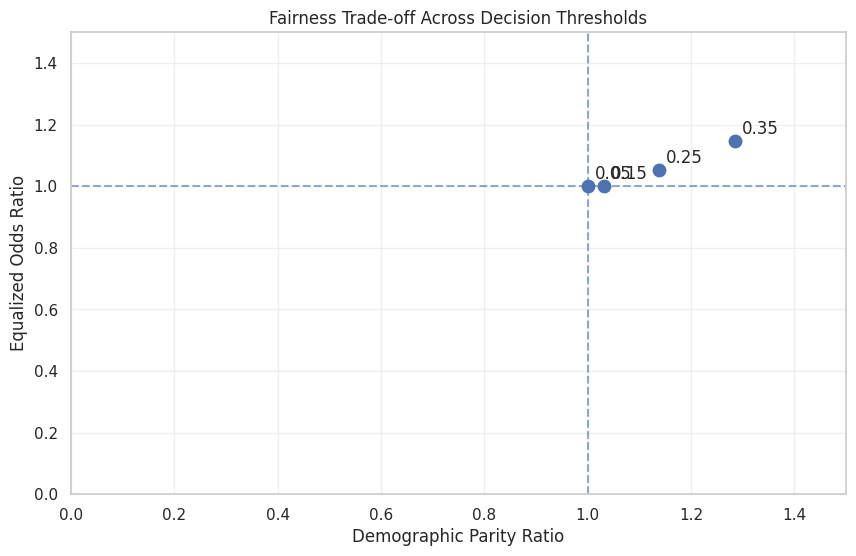

In [29]:
plt.figure(figsize=(10, 6))

plt.scatter(
    fairness_results["DP Ratio"],
    fairness_results["EO Ratio"],
    s=80
)

for _, row in fairness_results.iterrows():
    plt.annotate(
        str(row["Threshold"]),
        (row["DP Ratio"], row["EO Ratio"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.axvline(1, linestyle="--", alpha=0.6)
plt.axhline(1, linestyle="--", alpha=0.6)

plt.xlim(0, 1.5)
plt.ylim(0, 1.5)

plt.xlabel("Demographic Parity Ratio")
plt.ylabel("Equalized Odds Ratio")
plt.title("Fairness Trade-off Across Decision Thresholds")

plt.grid(alpha=0.3)
plt.show()

In [32]:
race_subset_mask = train_race.isin([
    "African-American", "Caucasian"
])

X_interaction = X_train.loc[
    race_subset_mask, subgroup_features
].copy()

y_interaction = yB_train.loc[race_subset_mask]

race_interaction = train_race.loc[race_subset_mask]

X_interaction["race_AA"] = (
    race_interaction == "African-American"
).astype(int)

X_interaction["priors_race_interaction"] = (
    X_interaction["priors_count"] *
    X_interaction["race_AA"]
)

X_interaction = sm.add_constant(
    X_interaction, has_constant="add"
)

interaction_model = sm.GLM(
    y_interaction,
    X_interaction,
    family=sm.families.Binomial()
).fit()

print(interaction_model.summary())

print("\nInteraction coefficient:")
print(interaction_model.params["priors_race_interaction"])

print("\nInteraction p-value:")
print(interaction_model.pvalues["priors_race_interaction"])

print("\nInteraction confidence interval:")
print(
    interaction_model.conf_int().loc[
        "priors_race_interaction"
    ]
)

                 Generalized Linear Model Regression Results                  
Dep. Variable:               is_recid   No. Observations:                 4298
Model:                            GLM   Df Residuals:                     4288
Model Family:                Binomial   Df Model:                            9
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2640.6
Date:                Thu, 19 Nov 2026   Deviance:                       5281.1
Time:                        16:20:31   Pearson chi2:                 4.56e+03
No. Iterations:                     5   Pseudo R-squ. (CS):             0.1457
Covariance Type:            nonrobust                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

In [33]:
adversarial_sample = adversarial_details.sample(
    n=50,
    random_state=100
)

print("Sample size:", len(adversarial_sample))

print("\nError types:")
display(adversarial_sample["error_type"].value_counts())

print("\nSex distribution:")
display(
    adversarial_sample["sex"].value_counts(normalize=True) * 100
)

print("\nRace distribution:")
display(
    adversarial_sample["race"].value_counts(normalize=True) * 100
)

print("\nAverage age:")
print(adversarial_sample["age"].mean())

print("\nAverage prior convictions:")
print(adversarial_sample["priors_count"].mean())

print("\nCharge degree:")
display(
    adversarial_sample["c_charge_degree"].value_counts()
)

Sample size: 50

Error types:


,count
error_type,
Confident False Negative,26
Confident False Positive,24



Sex distribution:


,proportion
sex,
Male,84.0
Female,16.0



Race distribution:


,proportion
race,
African-American,48.0
Caucasian,32.0
Hispanic,12.0
Other,6.0
Asian,2.0



Average age:
46.8

Average prior convictions:
7.06

Charge degree:


,count
c_charge_degree,
F,30
M,20


In [34]:
print("Male percentage in full test set:")
print(
    (df.loc[X_test.index, "sex"] == "Male").mean() * 100
)

print("\nMale percentage in adversarial sample:")
print(
    (adversarial_sample["sex"] == "Male").mean() * 100
)

print("\nAverage priors in full test set:")
print(df.loc[X_test.index, "priors_count"].mean())

print("\nAverage priors in adversarial sample:")
print(adversarial_sample["priors_count"].mean())

Male percentage in full test set:
80.36951501154735

Male percentage in adversarial sample:
84.0

Average priors in full test set:
3.636027713625866

Average priors in adversarial sample:
7.06


In [35]:
print("Average prior convictions by error type:")

display(
    adversarial_sample.groupby("error_type")[
        "priors_count"
    ].agg(["count", "mean", "median", "min", "max"])
)

Average prior convictions by error type:


,count,mean,median,min,max
error_type,,,,,
Confident False Negative,26,0.730769,1.0,0,3
Confident False Positive,24,13.916667,14.0,6,27
